## QML
https://quantum.cloud.ibm.com/learning/en/courses/quantum-machine-learning/introduction

In [10]:
# %pip install -r ../requirements.txt

In [11]:
# Import some qiskit packages required for setting up our quantum circuits.
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit
from qiskit.circuit.library import unitary_overlap

# Import StatevectorSampler as our sampler.
from qiskit.primitives import StatevectorSampler


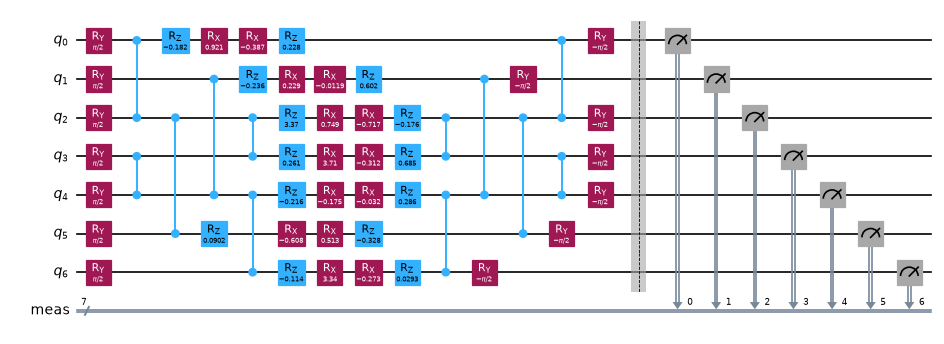

In [12]:
# Step 1: Map classical inputs to a quantum problem:

# Start by getting some appropriate data.
# The data imported below consist of 128 rows or data points.
# Each row has 14 columns that correspond to data features, and a 15th column with a label (+/-1).
# !wget https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv
import urllib.request
url = "https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv"
urllib.request.urlretrieve(url, "dataset_graph7.csv")

# Import some required packages, and write a function to pull some
# training data out of the csv file you got above.
import pandas as pd
import numpy as np


def get_training_data():
    """Read the training data."""
    df = pd.read_csv("dataset_graph7.csv", sep=",", header=None)
    training_data = df.values[:20, :]
    ind = np.argsort(training_data[:, -1])
    X_train = training_data[ind][:, :-1]

    return X_train


# Prepare training data
X_train = get_training_data()

# Empty kernel matrix
num_samples = np.shape(X_train)[0]

# Prepare feature map for computing overlap between two data points.
# This could be pre-built feature maps like ZZFeatureMap, or a custom quantum circuit,
# as shown here.
num_features = np.shape(X_train)[1]
num_qubits = int(num_features / 2)
entangler_map = [[0, 2], [3, 4], [2, 5], [1, 4], [2, 3], [4, 6]]
fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits)
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)

# Pick two data points, here 14 and 19, and assign the features to the circuits as parameters.
x1 = 14
x2 = 19
unitary1 = fm.assign_parameters(list(X_train[x1]) + [np.pi / 2])
unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2])

# Create the overlap circuit
overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()
overlap_circ.draw("mpl", scale=0.6, style="iqp")

In [17]:
import os
from dotenv import load_dotenv

# Load the .env file
load_dotenv()

# Retrieve the value using os.getenv
quantum_api_key = os.getenv("QUANTUM_API_KEY")
# print(f"Your API Key is: {quantum_api_key}")

In [18]:
# Step 2: Optimize problem for quantum execution

# Use IBM Quantum Compute Service to get the least busy backend for running on real quantum computers.
from qiskit_ibm_runtime import QiskitRuntimeService

# service = QiskitRuntimeService(channel="ibm_quantum")
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=quantum_api_key)
backend = service.least_busy(
   operational=True, simulator=False, min_num_qubits=overlap_circ.num_qubits
)

# Transpile the circuits optimally for the chosen backend using a pass manager.
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
overlap_ibm = pm.run(overlap_circ)



qiskit_runtime_service._discover_account:WARNING:2026-11-12 19:19:58,929: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-12 19:20:07,109: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: surnandi. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-12 19:20:07,659: Loading instance: surnandi, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-12 19:20:10,542: Using instance: surnandi, plan: open


In [19]:
# Step 3: Execute using IBM Quantum primitives

# Specify the number of shots to use.
num_shots = 10_000

## Evaluate the problem using statevector-based primitives from Qiskit
sampler = StatevectorSampler()
counts = (
    sampler.run([overlap_circ], shots=num_shots).result()[0].data.meas.get_int_counts()
)



In [20]:
# Step 4: Analyze and post-processing

# Find the probability of 0.
counts.get(0, 0.0) / num_shots

0.8167